# Step 1: **Import Libraries**



In [1]:
# importing libraries
import pandas as pd
import scipy
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt

# Step 2: **Load Dataset**

In [2]:
# Load the dataset with correct delimiter
file_path = r"PortScan.pcap_ISCX.csv"
df = pd.read_csv(file_path, delimiter=',') 

# Strip column names of any whitespace
df.columns = df.columns.str.strip()

# Handle missing values
df = df.dropna()

# Display dataset information
class_counts = df['Label'].value_counts()
class_percentages = df['Label'].value_counts(normalize=True) * 100
num_observations = df.shape[0]
num_attributes = df.shape[1]

# Print results
print("\nClass Distribution:\n", class_counts)
print("\nClass Percentages:\n", class_percentages)
print("\nNumber of observations: ", num_observations)
print("\nNumber of attributes: ", num_attributes)
print("\nCleaned Column Names:\n", df.columns.tolist())




Class Distribution:
 Label
PortScan    158930
BENIGN      127522
Name: count, dtype: int64

Class Percentages:
 Label
PortScan    55.482245
BENIGN      44.517755
Name: proportion, dtype: float64

Number of observations:  286452

Number of attributes:  79

Cleaned Column Names:
 ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd P

In [3]:
#Check the data info
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 286452 entries, 0 to 286466
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             286452 non-null  int64  
 1   Flow Duration                286452 non-null  int64  
 2   Total Fwd Packets            286452 non-null  int64  
 3   Total Backward Packets       286452 non-null  int64  
 4   Total Length of Fwd Packets  286452 non-null  int64  
 5   Total Length of Bwd Packets  286452 non-null  int64  
 6   Fwd Packet Length Max        286452 non-null  int64  
 7   Fwd Packet Length Min        286452 non-null  int64  
 8   Fwd Packet Length Mean       286452 non-null  float64
 9   Fwd Packet Length Std        286452 non-null  float64
 10  Bwd Packet Length Max        286452 non-null  int64  
 11  Bwd Packet Length Min        286452 non-null  int64  
 12  Bwd Packet Length Mean       286452 non-null  float64
 13  Bwd 

In [4]:
#Check the null value
df.isnull().sum()

Destination Port               0
Flow Duration                  0
Total Fwd Packets              0
Total Backward Packets         0
Total Length of Fwd Packets    0
                              ..
Idle Mean                      0
Idle Std                       0
Idle Max                       0
Idle Min                       0
Label                          0
Length: 79, dtype: int64

In [5]:
print(df.columns.tolist())


['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

Plot Correlation Heatmap

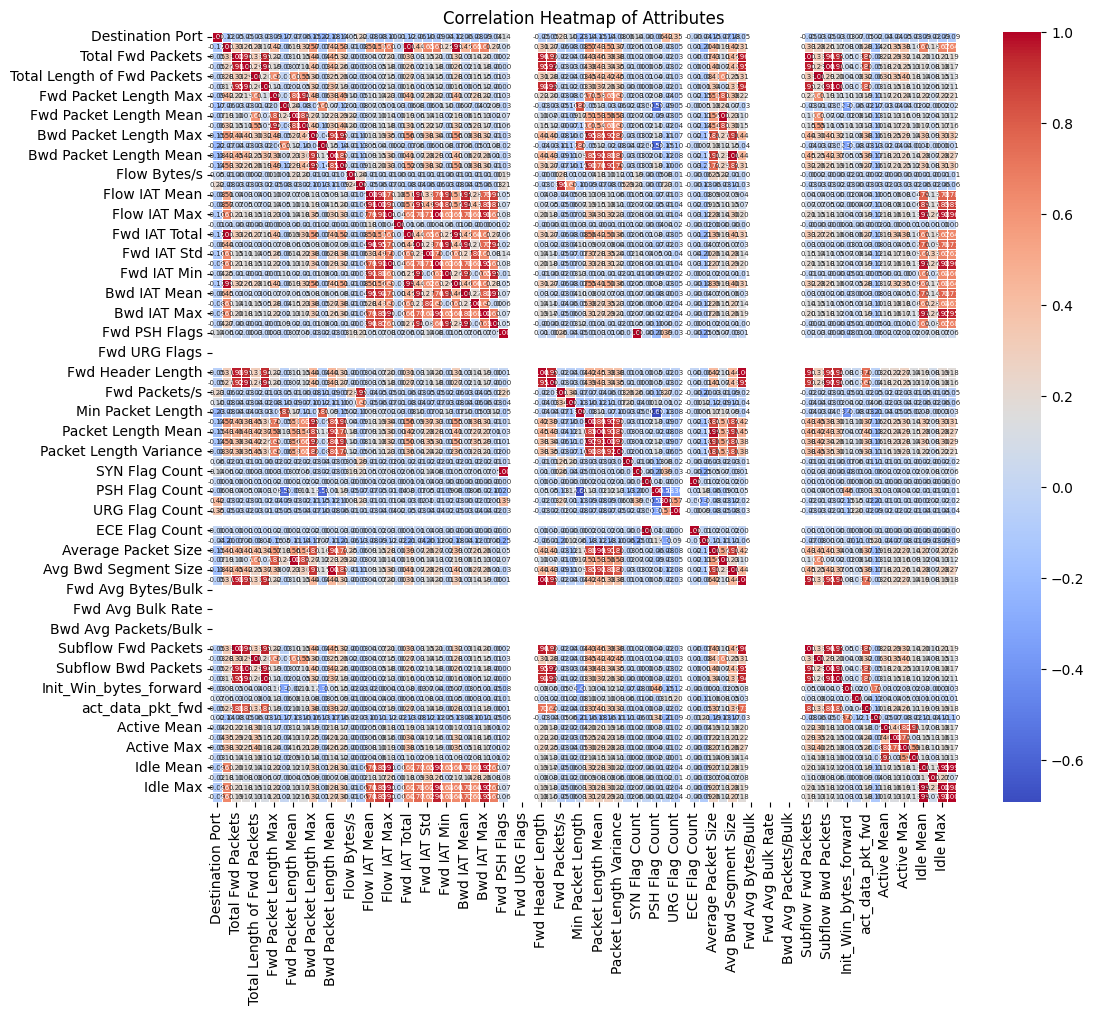

In [6]:
# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=[np.number])

# Calculate and plot the correlation matrix
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, annot_kws={"size": 5}, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Attributes")
plt.show()

# Step 3: **Feature Selection**

In [7]:
# Strip whitespace from all column names
df.columns = df.columns.str.strip()

# Define the top-priority features (now using the cleaned column names)
top_priority_features = [
    'Total Fwd Packets',
    'Total Backward Packets',
    'Flow Duration',
    'Flow Packets/s',
    'Flow Bytes/s',
    'Fwd Packet Length Max',
    'Fwd Packet Length Mean',
    'Fwd Packet Length Std',
    'SYN Flag Count',
    'FIN Flag Count',
    'RST Flag Count',
    'Down/Up Ratio',
    'Min Packet Length',
    'Max Packet Length',
    'Packet Length Mean',
    'Label'
]

# Check for missing columns just in case
missing = [col for col in top_priority_features if col not in df.columns]
if missing:
    print("Missing columns:", missing)
else:
    # Filter the dataset
    df_filtered = df[top_priority_features].dropna()

df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 286452 entries, 0 to 286466
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Total Fwd Packets       286452 non-null  int64  
 1   Total Backward Packets  286452 non-null  int64  
 2   Flow Duration           286452 non-null  int64  
 3   Flow Packets/s          286452 non-null  float64
 4   Flow Bytes/s            286452 non-null  float64
 5   Fwd Packet Length Max   286452 non-null  int64  
 6   Fwd Packet Length Mean  286452 non-null  float64
 7   Fwd Packet Length Std   286452 non-null  float64
 8   SYN Flag Count          286452 non-null  int64  
 9   FIN Flag Count          286452 non-null  int64  
 10  RST Flag Count          286452 non-null  int64  
 11  Down/Up Ratio           286452 non-null  int64  
 12  Min Packet Length       286452 non-null  int64  
 13  Max Packet Length       286452 non-null  int64  
 14  Packet Length Mean      2

# STEP 4: **Statistical Analysis**

In [8]:
#Descriptive overview of statistical analysis
df_filtered.describe()

c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Total Fwd Packets,Total Backward Packets,Flow Duration,Flow Packets/s,Flow Bytes/s,Fwd Packet Length Max,Fwd Packet Length Mean,Fwd Packet Length Std,SYN Flag Count,FIN Flag Count,RST Flag Count,Down/Up Ratio,Min Packet Length,Max Packet Length,Packet Length Mean
count,286452.000000,286452.000000,2.864520e+05,2.864520e+05,2.864520e+05,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000,286452.000000
mean,3.473392,3.520653,5.379612e+06,inf,inf,81.037612,24.139952,24.592282,0.020995,0.008693,0.000073,0.850638,10.125438,206.793969,47.865901
std,19.515636,28.289648,2.192418e+07,NaN,NaN,327.776093,78.383399,117.220977,0.143367,0.092828,0.008562,0.450203,18.768997,636.628927,122.034076
min,1.000000,0.000000,-1.300000e+01,-2.000000e+06,-1.930000e+08,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,4.400000e+01,1.664517e+02,7.928593e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,6.000000,2.000000
50%,1.000000,1.000000,6.500000e+01,3.076923e+04,1.250000e+05,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,6.000000,3.333333
75%,2.000000,2.000000,2.380600e+04,4.545455e+04,1.904762e+05,37.000000,34.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,77.000000,53.000000
max,3119.000000,3635.000000,1.199999e+08,inf,inf,13929.000000,3412.938776,3541.466551,1.000000,1.000000,1.000000,124.000000,289.000000,13929.000000,1588.000000


# Step 5: **Check Outliers**

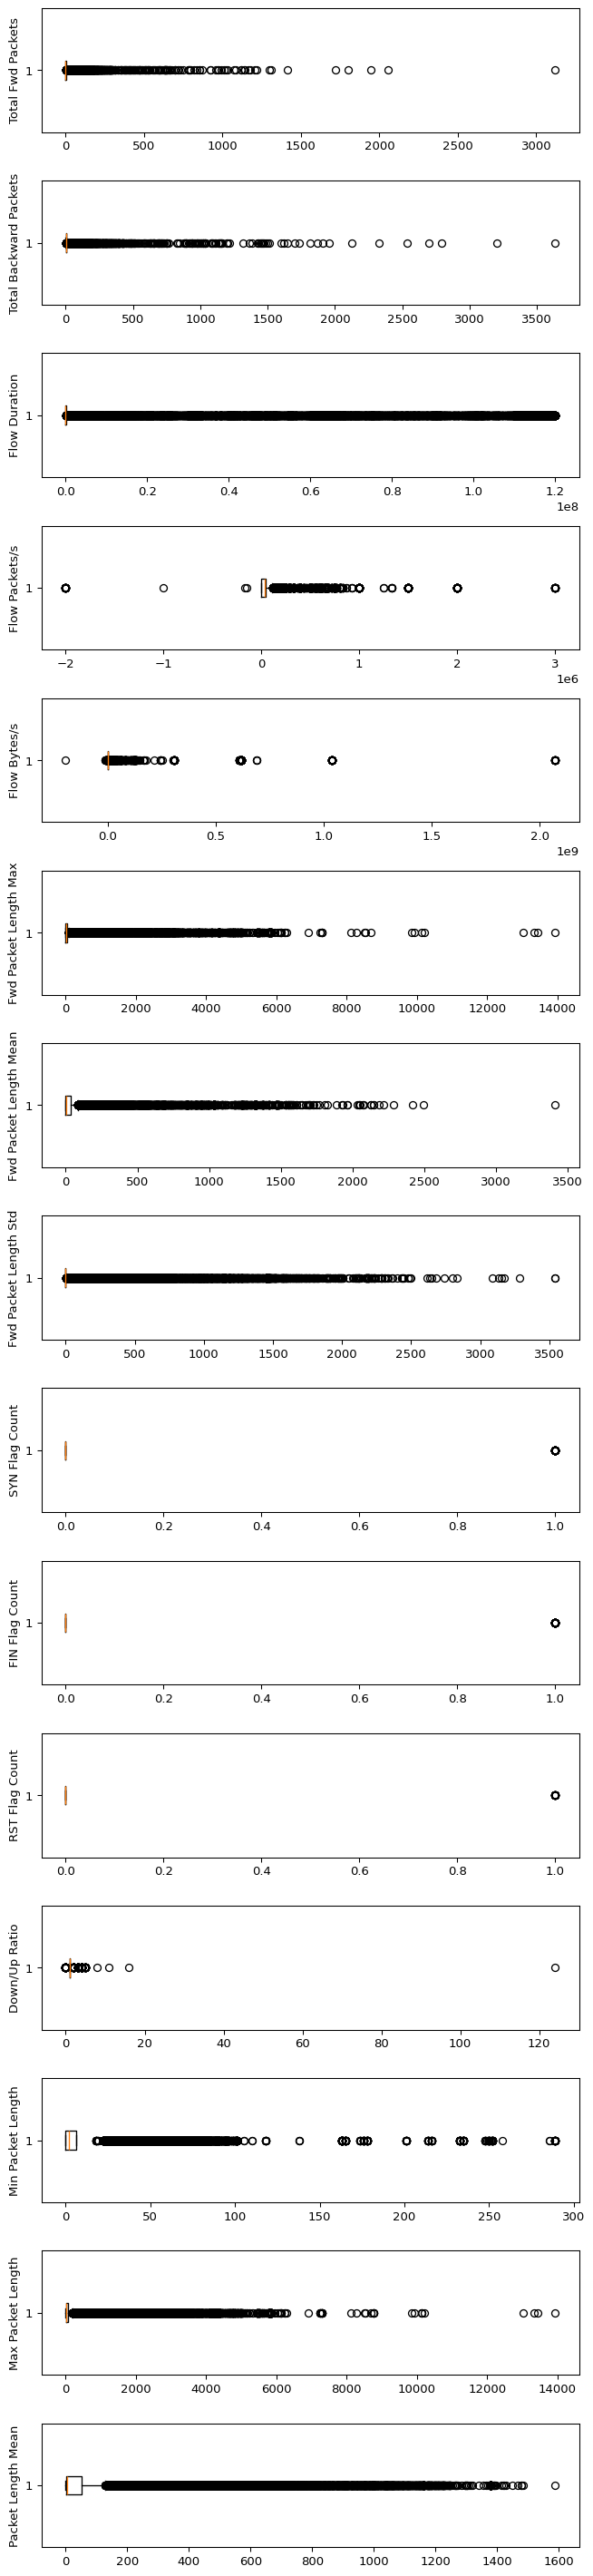

In [9]:
# Box Plots
fig, axs = plt.subplots(len(df_filtered.select_dtypes(include=['number']).columns), 1, dpi=95, figsize=(7, len(df_filtered.select_dtypes(include=['number']).columns)*2))

i = 0
for col in df_filtered.select_dtypes(include=['number']).columns: # Select only numeric columns for box plots
    axs[i].boxplot(df[col], vert=False)
    axs[i].set_ylabel(col)
    i += 1

plt.tight_layout() # Adjust subplot spacing for better readability
plt.show()

In [10]:
# Clean column names to remove leading/trailing spaces and invisible characters
df_filtered.columns = df_filtered.columns.str.strip()

# Step 6: **Drop the Outliers**

In [11]:
# Identify the quartiles for 'Total Fwd Packets'
q1, q3 = np.percentile(df['Total Fwd Packets'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
# Drop the outliers
clean_data = df[(df['Total Fwd Packets'] >= lower_bound)
                & (df['Total Fwd Packets'] <= upper_bound)]



# Identify the quartiles for variables 'Total Backwards Packets'
q1, q3 = np.percentile(clean_data['Total Backward Packets'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
# Drop the outliers
clean_data = clean_data[(clean_data['Total Backward Packets'] >= lower_bound)
                        & (clean_data['Total Backward Packets'] <= upper_bound)]


# Identify the quartiles for 'Flow Packets/s'
q1, q3 = np.percentile(clean_data['Flow Packets/s'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
# Drop the outliers
clean_data = clean_data[(clean_data['Flow Packets/s'] >= lower_bound)
                        & (clean_data['Flow Packets/s'] <= upper_bound)]


# Identify the quartiles for 'Flow Bytes/s'
q1, q3 = np.percentile(clean_data['Flow Bytes/s'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
# Drop the outliers
clean_data = clean_data[(clean_data['Flow Bytes/s'] >= lower_bound)
                        & (clean_data['Flow Bytes/s'] <= upper_bound)]


# Identify the quartiles for Fwd Packet Length Max
q1, q3 = np.percentile(clean_data['Fwd Packet Length Max'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (0.75 * iqr)
upper_bound = q3 + (0.75 * iqr)
# Drop the outliers
clean_data = clean_data[(clean_data['Fwd Packet Length Max'] >= lower_bound)
                        & (clean_data['Fwd Packet Length Max'] <= upper_bound)]


# Identify the quartiles for 'Fwd Packet Length Mean'
q1, q3 = np.percentile(clean_data['Fwd Packet Length Mean'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
# Drop the outliers
clean_data = clean_data[(clean_data['Fwd Packet Length Mean'] >= lower_bound)
                        & (clean_data['Fwd Packet Length Mean'] <= upper_bound)]


# Identify the quartiles for 'Fwd Packet Length Std'
q1, q3 = np.percentile(clean_data['Fwd Packet Length Std'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['Fwd Packet Length Std'] >= lower_bound)
                        & (clean_data['Fwd Packet Length Std'] <= upper_bound)]


# Identify the quartiles for 'SYN Flag Count'
q1, q3 = np.percentile(clean_data['SYN Flag Count'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['SYN Flag Count'] >= lower_bound)
                        & (clean_data['SYN Flag Count'] <= upper_bound)]


# Identify the quartiles for 'FIN Flag Count'
q1, q3 = np.percentile(clean_data['FIN Flag Count'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['FIN Flag Count'] >= lower_bound)
                        & (clean_data['FIN Flag Count'] <= upper_bound)]


# Identify the quartiles for 'RST Flag Count'
q1, q3 = np.percentile(clean_data['RST Flag Count'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['RST Flag Count'] >= lower_bound)
                        & (clean_data['RST Flag Count'] <= upper_bound)]


# Identify the quartiles for 'Down/Up Ratio'
q1, q3 = np.percentile(clean_data['Down/Up Ratio'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['Down/Up Ratio'] >= lower_bound)
                        & (clean_data['Down/Up Ratio'] <= upper_bound)]


# Identify the quartiles for 'Min Packet Length'
q1, q3 = np.percentile(clean_data['Min Packet Length'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['Min Packet Length'] >= lower_bound)
                        & (clean_data['Min Packet Length'] <= upper_bound)]


# Identify the quartiles for 'Max Packet Length'
q1, q3 = np.percentile(clean_data['Max Packet Length'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['Max Packet Length'] >= lower_bound)
                        & (clean_data['Max Packet Length'] <= upper_bound)]


# Identify the quartiles for ' Packet Length Mean'
q1, q3 = np.percentile(clean_data['Packet Length Mean'], [25, 75])
# Calculate the interquartile range
iqr = q3 - q1
# Calculate the lower and upper bounds
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Drop the outliers
clean_data = clean_data[(clean_data['Packet Length Mean'] >= lower_bound)
                        & (clean_data['Packet Length Mean'] <= upper_bound)]

# Step 7: **Correlation**

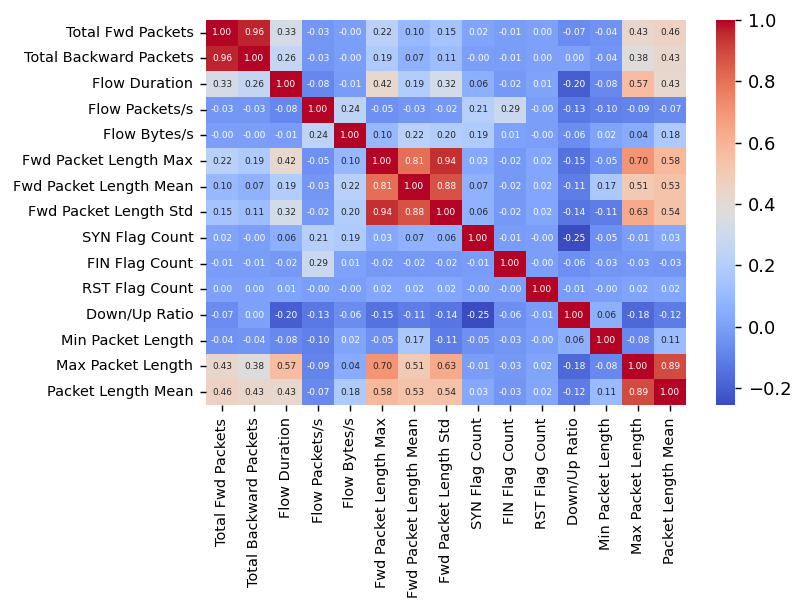

In [12]:
#correlation
# Select only numeric columns for correlation calculation
numeric_df = df_filtered.select_dtypes(include=['number'])

corr = numeric_df.corr()

plt.figure(dpi=130)
heatmap = sns.heatmap(corr, annot=True, fmt= '.2f', annot_kws={"size": 5}, cmap="coolwarm") # Set annotation font size here

# Adjusting tick labels
plt.xticks(fontsize=8)  # Change the font size of x-axis labels
plt.yticks(fontsize=8)  # Change the font size of y-axis labels

plt.tight_layout() # Adjust subplot spacing for better readability
plt.show()

Save new cleaned dataset

In [20]:
# Save the cleaned dataframe to a new CSV file
df_filtered.to_csv('cleaned_PortScan.pcap_ISCX.csv', index=False)

# Step 8: **Standardization**

In [13]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X = df_filtered.drop(columns=['Label'])  # Features
y = df_filtered['Label']  # Target

# Before splitting the data, encode the 'Label' column
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # Encode the 'Label' column

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Replace infinite values with NaN
X_train.replace([np.inf, -np.inf], np.nan, inplace=True)

# Impute NaN values with the mean of the column
# You can use other imputation strategies if you prefer
for col in X_train.columns:
    X_train[col] = X_train[col].fillna(X_train[col].mean())

# Replace infinite values with NaN in X_test
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# Impute NaN values in X_test with the mean of the column (or other strategy)
for col in X_test.columns:
    X_test[col] = X_test[col].fillna(X_test[col].mean())  # Using mean for imputation
    

# Standardize the features for SVM and K-NN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
dt_model = DecisionTreeClassifier(random_state=42)
svm_model = SVC(random_state=42)
knn_model = KNeighborsClassifier()



Train and Evaluate **Decision Tree (DT)** model

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)

# Step 2: Clean column names and check label
df_filtered.columns = df_filtered.columns.str.strip()
if 'Label' not in df_filtered.columns:
    raise ValueError("The dataset must have a 'Label' column.")

# Step 3: Encode target label if needed
if df_filtered['Label'].dtype == 'object':
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    df_filtered['Label'] = label_encoder.fit_transform(df_filtered['Label'])

# Step 4: Handle infinite and missing values
data = df_filtered.replace([np.inf, -np.inf], np.nan)
data = df_filtered.dropna()

# Step 5: Separate features and target
X = df_filtered.drop('Label', axis=1)
y = df_filtered['Label']

# Step 6: Initialize metric lists
n_runs = 100
accuracy_list = []
balanced_accuracy_list = []
precision_list = []
recall_list = []
f1_score_list = []
specificity_list = []

# Step 7: Training loop
for run in range(n_runs):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=run
    )
    
    clf = DecisionTreeClassifier(random_state=run, max_depth=5)
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    specificity_per_class = []
    for i in range(cm.shape[0]):
        tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
        fp = np.sum(cm[:, i]) - cm[i, i]
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_per_class.append(specificity)
    
    accuracy_list.append(accuracy_score(y_test, y_pred))
    balanced_accuracy_list.append(balanced_accuracy_score(y_test, y_pred))
    precision_list.append(precision_score(y_test, y_pred, average='weighted', zero_division=0))
    recall_list.append(recall_score(y_test, y_pred, average='weighted', zero_division=0))
    f1_score_list.append(f1_score(y_test, y_pred, average='weighted', zero_division=0))
    specificity_list.append(np.mean(specificity_per_class))

# Step 8: Initialize Decision Tree model
dt = DecisionTreeClassifier(random_state=42)

# Step 9: Set up Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Step 10: Evaluate using cross-validation
dt_scores = cross_val_score(dt, X_scaled, y, cv=cv, scoring='accuracy')

# Step 11: Output the results
print("Decision Tree Cross-Validation Accuracy Scores:", dt_scores)
print(f"Average CV Accuracy (DT): {dt_scores.mean()*100:.2f}%")

# Step 8: Report metrics
print("Average Metrics Across 100 Runs (Decision Tree):")
print(f"Accuracy: {np.mean(accuracy_list) * 100:.2f}%")
print(f"Balanced Accuracy: {np.mean(balanced_accuracy_list) * 100:.2f}%")
print(f"Precision: {np.mean(precision_list) * 100:.2f}%")
print(f"Recall: {np.mean(recall_list) * 100:.2f}%")
print(f"F1-Score: {np.mean(f1_score_list) * 100:.2f}%")
print(f"Specificity: {np.mean(specificity_list) * 100:.2f}%")


Decision Tree Cross-Validation Accuracy Scores: [0.99973785 0.99986019 0.99989514 0.99984271 0.99984271]
Average CV Accuracy (DT): 99.98%
Average Metrics Across 100 Runs (Decision Tree):
Accuracy: 99.90%
Balanced Accuracy: 99.90%
Precision: 99.90%
Recall: 99.90%
F1-Score: 99.90%
Specificity: 99.90%


Train and Evaluate **k-NN** model

In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)
# Step 2: Clean column names
df_filtered.columns = df_filtered.columns.str.strip()

# Step 3: Verify 'Label' column exists
if 'Label' not in df_filtered.columns:
    raise ValueError("The dataset must have a 'Label' column.")

# Step 4: Encode the target label if necessary
if df_filtered['Label'].dtype == 'object':
    label_encoder = LabelEncoder()
    df_filtered['Label'] = label_encoder.fit_transform(df_filtered['Label'])

# Step 5: Handle infinite and missing values
df_filtered = df_filtered.replace([np.inf, -np.inf], np.nan)
df_filtered = df_filtered.dropna()

# Step 6: Separate features and target
X = df_filtered.drop('Label', axis=1)
y = df_filtered['Label']

# Step 7: Scale the features (important for K-NN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Step 8: Cross-Validation
# Initialize the model
knn = KNeighborsClassifier(n_neighbors=5)

# Set up Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate using cross-validation
scores = cross_val_score(knn, X_scaled, y, cv=cv, scoring='accuracy')

print("Cross-Validation Accuracy Scores:", scores)
print(f"Average CV Accuracy: {scores.mean()*100:.2f}%")

# Step 9: Initialize metric lists
n_runs = 100
accuracy_list = []
balanced_accuracy_list = []
precision_list = []
recall_list = []
f1_score_list = []
specificity_list = []

# Step 9: Run K-NN multiple times
for run in range(n_runs):
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.2, random_state=run
    )

    # Train K-NN (k=5 as default)
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train, y_train)
    
    y_pred = knn.predict(X_test)

    # Confusion matrix and specificity
    cm = confusion_matrix(y_test, y_pred)
    specificity_per_class = []
    for i in range(cm.shape[0]):
        tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
        fp = np.sum(cm[:, i]) - cm[i, i]
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_per_class.append(specificity)

    # Collect metrics
    accuracy_list.append(accuracy_score(y_test, y_pred))
    balanced_accuracy_list.append(balanced_accuracy_score(y_test, y_pred))
    precision_list.append(precision_score(y_test, y_pred, average='weighted', zero_division=0))
    recall_list.append(recall_score(y_test, y_pred, average='weighted', zero_division=0))
    f1_score_list.append(f1_score(y_test, y_pred, average='weighted', zero_division=0))
    specificity_list.append(np.mean(specificity_per_class))

# Step 10: Report average metrics
print("Average Metrics Across 100 Runs (K-NN):")
print(f"Accuracy: {np.mean(accuracy_list) * 100:.2f}%")
print(f"Balanced Accuracy: {np.mean(balanced_accuracy_list) * 100:.2f}%")
print(f"Precision: {np.mean(precision_list) * 100:.2f}%")
print(f"Recall: {np.mean(recall_list) * 100:.2f}%")
print(f"F1-Score: {np.mean(f1_score_list) * 100:.2f}%")
print(f"Specificity: {np.mean(specificity_list) * 100:.2f}%")


Cross-Validation Accuracy Scores: [0.99973785 0.99984271 0.99984271 0.99987766 0.99975533]
Average CV Accuracy: 99.98%
Average Metrics Across 100 Runs (K-NN):
Accuracy: 99.98%
Balanced Accuracy: 99.98%
Precision: 99.98%
Recall: 99.98%
F1-Score: 99.98%
Specificity: 99.98%


Train and Evaluate SVM model

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
from concurrent.futures import ThreadPoolExecutor

# === Step 1: Load and prepare your dataset (assume df_filtered is already loaded) ===

# Clean column names
df_filtered.columns = df_filtered.columns.str.strip()

# Ensure 'Label' column exists
if 'Label' not in df_filtered.columns:
    raise ValueError("The dataset must have a 'Label' column.")

# Encode label if it's categorical
if df_filtered['Label'].dtype == 'object':
    label_encoder = LabelEncoder()
    df_filtered['Label'] = label_encoder.fit_transform(df_filtered['Label'])

# Handle infinities and missing values
df_filtered.replace([np.inf, -np.inf], np.nan, inplace=True)
df_filtered.dropna(inplace=True)

# Split features and target
X = df_filtered.drop('Label', axis=1)
y = df_filtered['Label']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Step 2: Cross-validation using SVC ===
svm = SVC(kernel='linear', random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svm_scores = cross_val_score(svm, X_scaled, y, cv=cv, scoring='accuracy')

print("SVM Cross-Validation Accuracy Scores:", svm_scores)
print(f"Average CV Accuracy (SVM): {svm_scores.mean() * 100:.2f}%")

# === Step 3: Define parallel evaluation function ===
def run_svm_trial(run):
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, y, test_size=0.2, random_state=run
        )

        clf = LinearSVC(random_state=run, max_iter=10000)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        cm = confusion_matrix(y_test, y_pred)
        specificity_per_class = []
        for i in range(cm.shape[0]):
            tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
            fp = np.sum(cm[:, i]) - cm[i, i]
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
            specificity_per_class.append(specificity)

        return (
            accuracy_score(y_test, y_pred),
            balanced_accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, average='weighted', zero_division=0),
            recall_score(y_test, y_pred, average='weighted', zero_division=0),
            f1_score(y_test, y_pred, average='weighted', zero_division=0),
            np.mean(specificity_per_class)
        )
    except Exception as e:
        print(f"Run {run} failed with error: {e}")
        return (0, 0, 0, 0, 0, 0)

# === Step 4: Run evaluations in parallel ===
n_runs = 20
with ThreadPoolExecutor() as executor:
    results = list(executor.map(run_svm_trial, range(n_runs)))

# Unpack results
accuracy_list, balanced_accuracy_list, precision_list, recall_list, f1_score_list, specificity_list = map(
    lambda x: [r[x] for r in results], range(6)
)

# === Step 5: Report average metrics ===
print("\nAverage Metrics Across 20 Runs (Linear SVM):")
print(f"Accuracy: {np.mean(accuracy_list) * 100:.2f}%")
print(f"Balanced Accuracy: {np.mean(balanced_accuracy_list) * 100:.2f}%")
print(f"Precision: {np.mean(precision_list) * 100:.2f}%")
print(f"Recall: {np.mean(recall_list) * 100:.2f}%")
print(f"F1-Score: {np.mean(f1_score_list) * 100:.2f}%")
print(f"Specificity: {np.mean(specificity_list) * 100:.2f}%")



SVM Cross-Validation Accuracy Scores: [0.97032506 0.97402961 0.97397718 0.97387232 0.97392475]
Average CV Accuracy (SVM): 97.32%

Average Metrics Across 20 Runs (Linear SVM):
Accuracy: 94.01%
Balanced Accuracy: 93.37%
Precision: 94.44%
Recall: 94.01%
F1-Score: 93.96%
Specificity: 93.37%


# **Exploratory Data Analysis (EDA)**

# 1. Overview of the data

In [21]:
# 1. Overview of the Data
print("Shape of dataset:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe())

Shape of dataset: (140351, 47)

Data Types:
 Flow Duration                    int64
Total Fwd Packets                int64
Total Backward Packets           int64
Total Length of Fwd Packets      int64
Total Length of Bwd Packets      int64
Fwd Packet Length Max            int64
Fwd Packet Length Min            int64
Fwd Packet Length Mean         float64
Fwd Packet Length Std          float64
Bwd Packet Length Max            int64
Bwd Packet Length Min            int64
Bwd Packet Length Mean         float64
Bwd Packet Length Std          float64
Flow Bytes/s                   float64
Flow Packets/s                 float64
Flow IAT Mean                  float64
Flow IAT Std                   float64
Flow IAT Max                   float64
Flow IAT Min                   float64
Fwd IAT Total                  float64
Bwd IAT Total                  float64
Fwd PSH Flags                  float64
Bwd PSH Flags                  float64
Fwd URG Flags                  float64
Bwd URG Flags      

Checking for the duplicate values

In [22]:
#checking duplicate values
df.nunique()

,0
Flow Duration,45893
Total Fwd Packets,343
Total Backward Packets,428
Total Length of Fwd Packets,4555
Total Length of Bwd Packets,8437
Fwd Packet Length Max,2284
Fwd Packet Length Min,119
Fwd Packet Length Mean,9769
Fwd Packet Length Std,13010
Bwd Packet Length Max,2347


# Checking for the duplicate values

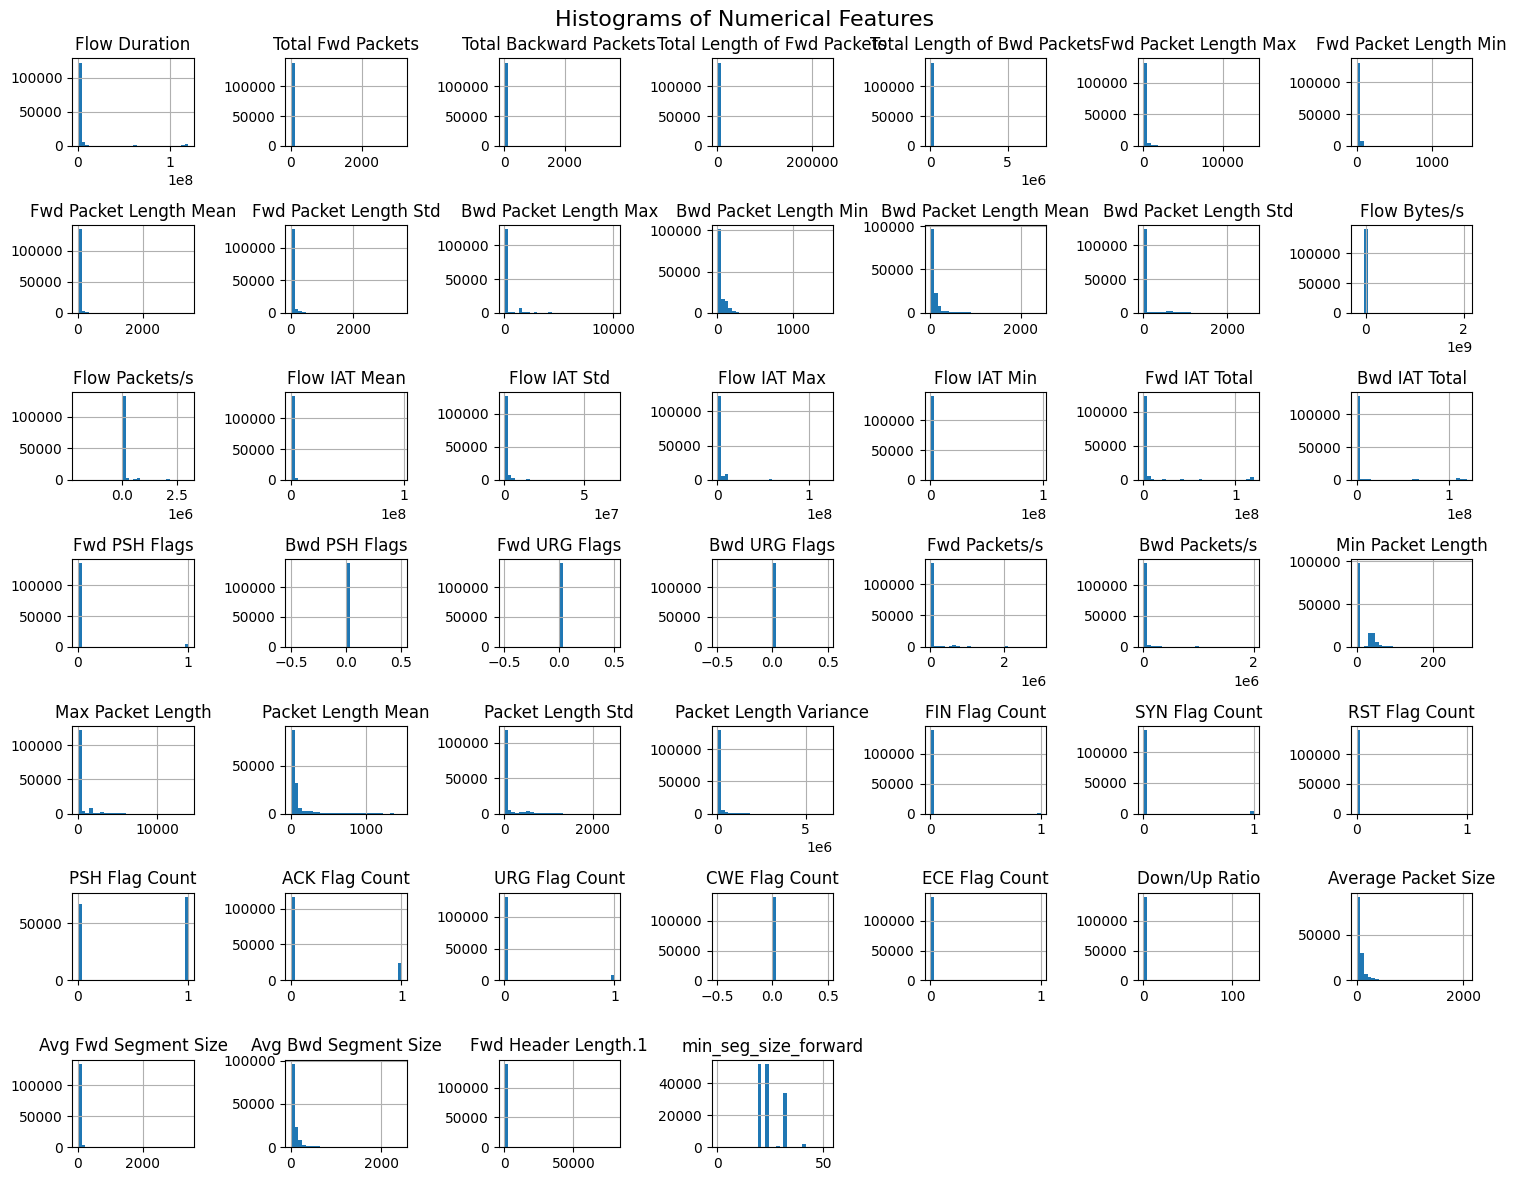

In [ ]:
# Visualizing distributions for numeric features
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

# Replace infinite values with NaN
df[numeric_columns] = df[numeric_columns].replace([np.inf, -np.inf], np.nan)



# Histograms for numerical features
df[numeric_columns].hist(figsize=(15, 12), bins=30)
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.tight_layout() # Adjust subplot spacing for better readability
plt.show()



# 3. Categorical Features Analysis (Count Plots, Pie Charts)

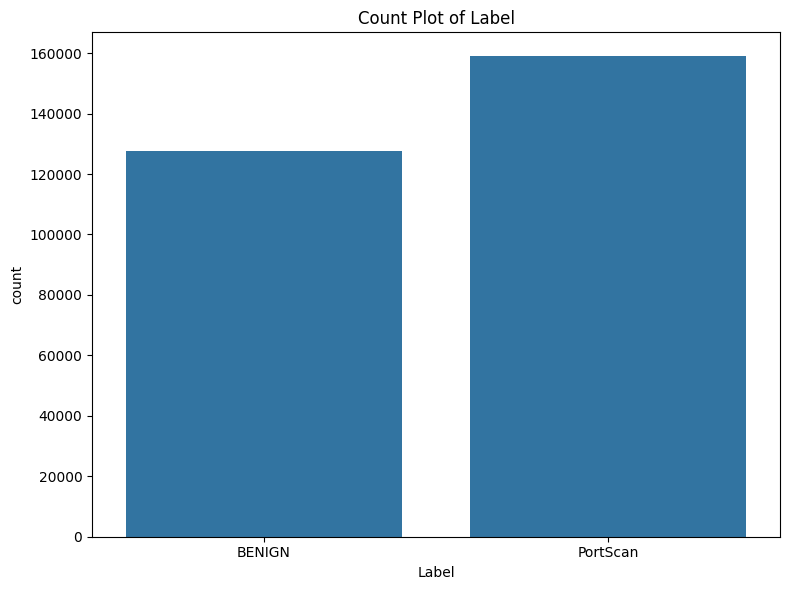

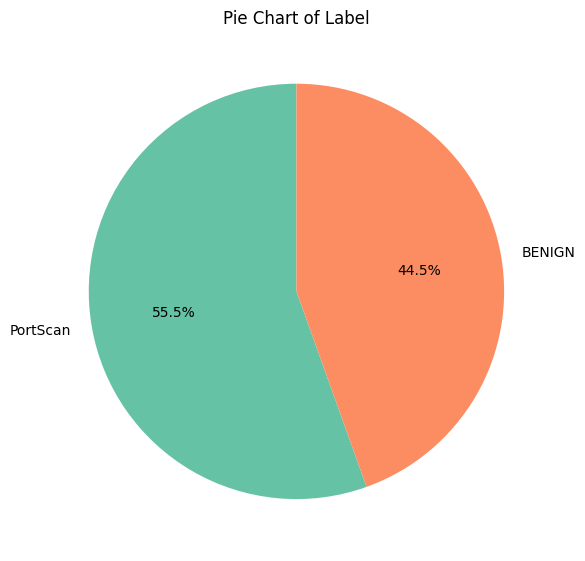

Class Counts:
Label
PortScan    158930
BENIGN      127522
Name: count, dtype: int64


In [24]:
# importing libraries
import pandas as pd
import scipy
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt


categorical_columns = df.select_dtypes(include=['object']).columns

# Count plots for categorical variables
for col in categorical_columns:
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x=col)
    plt.title(f'Count Plot of {col}')
    plt.tight_layout()
    plt.show()

# Pie charts for categorical features
for col in categorical_columns:
    plt.figure(figsize=(6, 6))
    df[col].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2', len(df[col].unique())))
    plt.title(f'Pie Chart of {col}')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

# Count the number of instances for each class in the 'Label' column
class_counts = df['Label'].value_counts()

# Display the counts
print("Class Counts:")
print(class_counts)


# 5. Missing Data Visualization

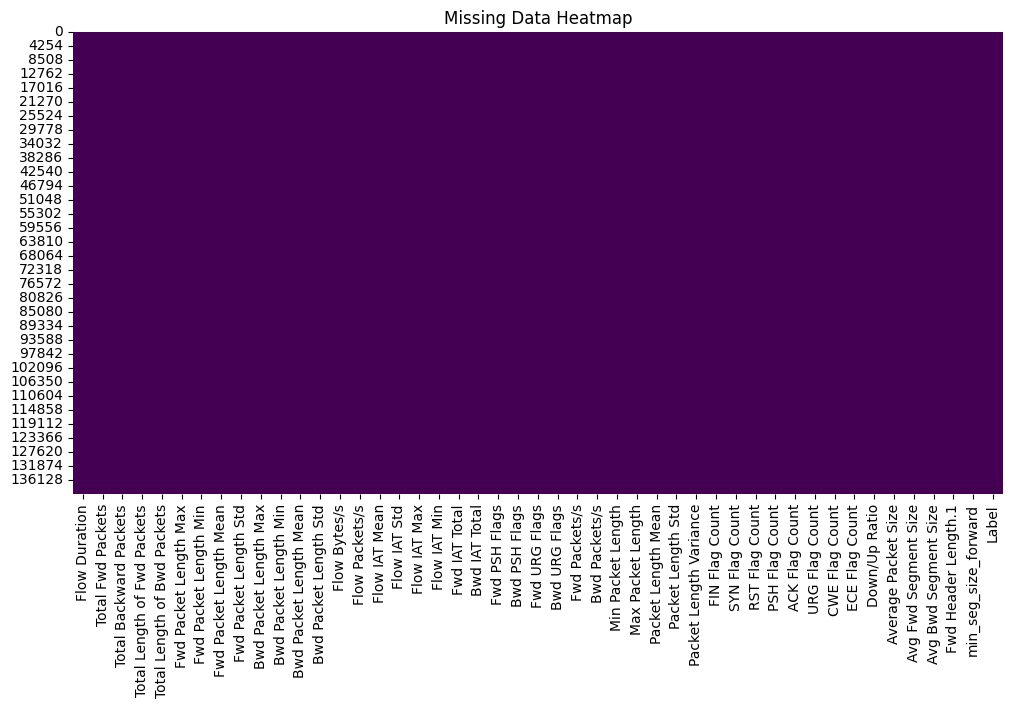

In [27]:
# Visualize missing data using a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

In [3]:
print(df.columns.tolist())


[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

Create risk_model.pkl

In [11]:
import pandas as pd

# Load CIC-IDS 2017 dataset
df = pd.read_csv("PortScan.pcap_ISCX.csv")

# Clean column names (remove leading/trailing whitespace)
df.columns = df.columns.str.strip()

# Check if 'Label' column exists
if "Label" not in df.columns:
    raise KeyError("The column 'Label' was not found in the dataset. Available columns: " + ", ".join(df.columns))

# Filter to just BENIGN and PortScan
df = df[df["Label"].isin(["BENIGN", "PortScan"])]

# Select features relevant to port scan behavior
features = [
    "Flow Duration", "Total Fwd Packets", "Fwd Packet Length Mean",
    "SYN Flag Count", "RST Flag Count", "Packet Length Mean", "Label"
]

# Ensure all required columns exist
missing = [col for col in features if col not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

df = df[features]

# Label: 1 = High Risk (PortScan), 0 = Low Risk (BENIGN)
df["Label"] = df["Label"].map({"BENIGN": 0, "PortScan": 1})

# Save processed data
df.to_csv("processed_risk.csv", index=False)



Train risk_model.pkl


In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pandas as pd
import joblib

df = pd.read_csv("processed_risk.csv")

X = df.drop("Label", axis=1)
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = DecisionTreeClassifier()
model.fit(X_train, y_train)

joblib.dump(model, "risk_model.pkl")


['risk_model.pkl']

Create alert_model.pkl

In [13]:
import pandas as pd

df = pd.read_csv("PortScan.pcap_ISCX.csv")

# Clean column names (remove leading/trailing whitespace)
df.columns = df.columns.str.strip()

# Check if 'Label' column exists
if "Label" not in df.columns:
    raise KeyError("The column 'Label' was not found in the dataset. Available columns: " + ", ".join(df.columns))


# Pick 3 classes only
def map_to_action(label):
    if label == "BENIGN":
        return 0  # Ignore
    elif label == "PortScan":
        return 2  # Terminate
    else:
        return 1  # Monitor (default for other threats)

df["Action"] = df["Label"].apply(map_to_action)

features = [
    "Flow Duration", "Total Fwd Packets", "Fwd Packet Length Mean",
    "SYN Flag Count", "RST Flag Count", "Packet Length Mean", "Action"
]
df = df[features]
df.to_csv("processed_alert.csv", index=False)


Train alert_model.pkl

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import pandas as pd
import joblib

df = pd.read_csv("processed_alert.csv")

X = df.drop("Action", axis=1)
y = df["Action"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = RandomForestClassifier()
model.fit(X_train, y_train)

joblib.dump(model, "alert_model.pkl")


['alert_model.pkl']

ML ALERT CENTRE DATASET

In [4]:
import pandas as pd
import numpy as np

# --- STEP 1: Load the dataset ---
df = pd.read_csv("UNSW_NB15_training-set.csv")
df.columns = df.columns.str.strip()  # clean headers

print("✅ Loaded dataset:", df.shape)
print("Columns:", list(df.columns))

# --- STEP 2: Identify correct column names ---
if 'srcip' in df.columns:
    src_col = 'srcip'
elif 'src' in df.columns:
    src_col = 'src'
else:
    # Create a fake IP identifier if missing
    df['srcip'] = ["192.168.{}.{}".format(np.random.randint(0, 255), i % 255)
                   for i in range(len(df))]
    src_col = 'srcip'
    print("⚠️ No srcip/src column found. Generated fake IP addresses for visualization.")

# --- STEP 3: Basic Cleaning ---
df = df.dropna(subset=[src_col]).drop_duplicates()

# --- STEP 4: Filter only attack rows ---
if 'label' in df.columns:
    df_attack = df[df['label'] == 1]
else:
    df_attack = df.copy()  # fallback if no 'label' column

# --- STEP 5: Group by source IP ---
grouped = df_attack.groupby(src_col).agg({
    'attack_cat': lambda x: x.mode()[0] if not x.mode().empty else 'Unknown',
    'dur': 'mean',
    'sbytes': 'sum',
    'dbytes': 'sum'
}).reset_index()

# --- STEP 6: Count attacks per IP ---
attack_counts = df_attack.groupby(src_col)['attack_cat'].count().reset_index(name='attack_count')
grouped = grouped.merge(attack_counts, on=src_col, how='left')

# --- STEP 7: Confidence score ---
grouped['confidence'] = np.clip(
    60 + (grouped['attack_count'] / grouped['attack_count'].max()) * 40,
    60, 99.9
).round(2)

# --- STEP 8: Map attack reason ---
reason_map = {
    'Reconnaissance': 'Reconnaissance activity detected',
    'DoS': 'Denial of Service attempt',
    'Exploits': 'Exploit pattern detected',
    'Fuzzers': 'Abnormal fuzzing behavior',
    'Generic': 'Generic attack behavior',
    'Shellcode': 'Shellcode injection attempt',
    'Worms': 'Worm propagation detected',
    'Backdoor': 'Backdoor connection attempt'
}
grouped['reason'] = grouped['attack_cat'].map(reason_map).fillna('Suspicious activity detected')

# --- STEP 9: Suggest action ---
def suggest_action(conf):
    if conf > 90:
        return "Block IP"
    elif conf > 75:
        return "Terminate session"
    else:
        return "Monitor"

grouped['action'] = grouped['confidence'].apply(suggest_action)

# --- STEP 10: Rename for consistency ---
grouped.rename(columns={src_col: 'ip'}, inplace=True)

# --- STEP 11: Save final CSV ---
final_df = grouped[['ip', 'attack_cat', 'dur', 'sbytes', 'dbytes', 'confidence', 'reason', 'action']]
final_df.to_csv('ml_action_training_data.csv', index=False)

print("\n✅ Preprocessed dataset saved as ml_action_training_data.csv")
print(final_df.head())


✅ Loaded dataset: (82332, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']
⚠️ No srcip/src column found. Generated fake IP addresses for visualization.

✅ Preprocessed dataset saved as ml_action_training_data.csv
              ip attack_cat       dur  sbytes  dbytes  confidence  \
0    192.168.0.0    Generic  0.000010     228       0       73.33   
1   192.168.0.10    Fuzzers  0.701937     588     354       66.67   
2  192.168.0.102   Exploits  0.000005     294       0       73.33   
3  192.168.0.107   Exploits  0